# Classification with Sparse Features

## Libraries import

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

pd.set_option('display.max_colwidth', None)

## Datasets import

In [2]:
df_books = pd.read_csv('Books.csv').drop(['Image-URL-S', 'Image-URL-M', 'Image-URL-L'], axis=1)
df_books.info()

D:\Download\distrib\VSCode\data\tmp\ipykernel_17848\2597578107.py:1: DtypeWarning: Columns (0: Year-Of-Publication) have mixed types. Specify dtype option on import or set low_memory=False.
  df_books = pd.read_csv('Books.csv').drop(['Image-URL-S', 'Image-URL-M', 'Image-URL-L'], axis=1)


<class 'pandas.DataFrame'>
RangeIndex: 271360 entries, 0 to 271359
Data columns (total 5 columns):
 #   Column               Non-Null Count   Dtype 
---  ------               --------------   ----- 
 0   ISBN                 271360 non-null  str   
 1   Book-Title           271360 non-null  str   
 2   Book-Author          271358 non-null  str   
 3   Year-Of-Publication  271360 non-null  object
 4   Publisher            271358 non-null  str   
dtypes: object(1), str(4)
memory usage: 30.6+ MB


In [3]:
df_ratings = pd.read_csv('Ratings.csv')
df_ratings.info()

<class 'pandas.DataFrame'>
RangeIndex: 1149780 entries, 0 to 1149779
Data columns (total 3 columns):
 #   Column       Non-Null Count    Dtype
---  ------       --------------    -----
 0   User-ID      1149780 non-null  int64
 1   ISBN         1149780 non-null  str  
 2   Book-Rating  1149780 non-null  int64
dtypes: int64(2), str(1)
memory usage: 37.3 MB


In [4]:
df_users = pd.read_csv('Users.csv')
df_users.info()

<class 'pandas.DataFrame'>
RangeIndex: 278858 entries, 0 to 278857
Data columns (total 3 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   User-ID   278858 non-null  int64  
 1   Location  278858 non-null  str    
 2   Age       168096 non-null  float64
dtypes: float64(1), int64(1), str(1)
memory usage: 13.4 MB


In [5]:
# Change columns names for more comfortable work and editing
df_books.columns = list(map(lambda x: x.replace('-', '_'), df_books.columns))
df_ratings.columns = list(map(lambda x: x.replace('-', '_'), df_ratings.columns))
df_users.columns = list(map(lambda x: x.replace('-', '_'), df_users.columns))

## EDA
### Books

In [6]:
df_books.head()

,ISBN,Book_Title,Book_Author,Year_Of_Publication,Publisher
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial
3,0374157065,Flu: The Story of the Great Influenza Pandemic of 1918 and the Search for the Virus That Caused It,Gina Bari Kolata,1999,Farrar Straus Giroux
4,0393045218,The Mummies of Urumchi,E. J. W. Barber,1999,W. W. Norton &amp; Company


In [7]:
# NaNs checking
df_books.isna().sum()

ISBN                   0
Book_Title             0
Book_Author            2
Year_Of_Publication    0
Publisher              2
dtype: int64

In [8]:
# Looking at NaNs
df_books[(df_books['Book_Author'].isna()) | (df_books['Publisher'].isna())]

,ISBN,Book_Title,Book_Author,Year_Of_Publication,Publisher
118033,0751352497,A+ Quiz Masters:01 Earth,NaN,1999,Dorling Kindersley
128890,193169656X,Tyrant Moon,Elaine Corvidae,2002,NaN
129037,1931696993,Finders Keepers,Linnea Sinclair,2001,NaN
187689,9627982032,The Credit Suisse Guide to Managing Your Personal Wealth,NaN,1995,Edinburgh Financial Publishing


In [9]:
# The A+ Quiz Masters:01 Earth has NaN in author column because it is studying book - convert NaN to string
df_books.loc[118033, 'Book_Author'] = 'NaN'

# For book 'The Credit suisse guide to managing your personal wealth' check out an author and fill in
df_books.loc[187689, 'Book_Author'] = 'Larissa Anne Downes' 

# For `Publisher` column change NaNs' type on string
df_books['Publisher'] = df_books['Publisher'].fillna('NaN')

In [10]:
# Checking possible duplicates in dfs' columns
print(f"df_books['ISBN']: {np.any(df_books['ISBN'].duplicated())}")
print(f"df_books['Book_Title']: {np.any(df_books['Book_Title'].duplicated())}")

df_books['ISBN']: False
df_books['Book_Title']: True


In [11]:
# Researching duplicated books' titles
duplicated_books_list = set(df_books[df_books['Book_Title'].duplicated()]['Book_Title'].tolist())
print(f'Duplicated books list length: {len(duplicated_books_list)}')
df_duplicated_books = df_books[df_books['Book_Title'].isin(duplicated_books_list)].reset_index(drop=True)
df_duplicated_books.head()

Duplicated books list length: 19907


,ISBN,Book_Title,Book_Author,Year_Of_Publication,Publisher
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press
1,0399135782,The Kitchen God's Wife,Amy Tan,1991,Putnam Pub Group
2,0425176428,What If?: The World's Foremost Military Historians Imagine What Might Have Been,Robert Cowley,2000,Berkley Publishing Group
3,074322678X,Where You'll Find Me: And Other Stories,Ann Beattie,2002,Scribner
4,1552041778,Jane Doe,R. J. Kaiser,1999,Mira Books


In [12]:
# Transform `Book_Title`, `Book_Author` and `Publisher` values into lower case to prevent errors because of letters' size
df_books['Book_Title'] = df_books['Book_Title'].apply(lambda x: x.lower())
df_books['Book_Author'] = df_books['Book_Author'].apply(lambda x: x.lower())
df_books['Publisher'] = df_books['Publisher'].apply(lambda x: x.lower())

In [13]:
# While EDA strange values and anomalies were also found
display(df_books[df_books['Publisher'] == 'Bottom Line Pre$$'])
display(df_books[~df_books['Year_Of_Publication'].astype('str').apply(lambda x: x.isnumeric())])

# Replace wrong name of 'Bottom Line Press'
df_books['Publisher'] = df_books['Publisher'].replace({'Bottom Line Pre$$': 'Bottom Line Press'})

# Fix the shift in rows
def shift_fixer(values):
    isbn, title_and_author, year, publisher = list(values)[:-1]
    title, author = title_and_author.split(u'\\";')
    return (isbn, title, author, year, publisher)

shift_inds = df_books[~df_books['Year_Of_Publication'].astype('str').apply(lambda x: x.isnumeric())].index
for i in shift_inds:
    df_books.loc[i] = shift_fixer(df_books.loc[i].values)

,ISBN,Book_Title,Book_Author,Year_Of_Publication,Publisher


,ISBN,Book_Title,Book_Author,Year_Of_Publication,Publisher
209538,078946697X,"dk readers: creating the x-men, how it all began (level 4: proficient readers)\"";michael teitelbaum""",2000,DK Publishing Inc,http://images.amazon.com/images/p/078946697x.01.thumbzzz.jpg
220731,2070426769,"peuple du ciel, suivi de 'les bergers\"";jean-marie gustave le clã?â©zio""",2003,Gallimard,http://images.amazon.com/images/p/2070426769.01.thumbzzz.jpg
221678,0789466953,"dk readers: creating the x-men, how comic books come to life (level 4: proficient readers)\"";james buckley""",2000,DK Publishing Inc,http://images.amazon.com/images/p/0789466953.01.thumbzzz.jpg


In [14]:
# The `Year_Of_Publication` has type `object` and some values have duplicates but in different types
# Also some of `Year_Of_Publication` values equal 0. Will refer to them as NaNs 
display(df_books['Year_Of_Publication'].unique())

# Fix it
df_books['Year_Of_Publication'] = df_books['Year_Of_Publication'].astype('int32')

array([2002, 2001, 1991, 1999, 2000, 1993, 1996, 1988, 2004, 1998, 1994,
       2003, 1997, 1983, 1979, 1995, 1982, 1985, 1992, 1986, 1978, 1980,
       1952, 1987, 1990, 1981, 1989, 1984, 0, 1968, 1961, 1958, 1974,
       1976, 1971, 1977, 1975, 1965, 1941, 1970, 1962, 1973, 1972, 1960,
       1966, 1920, 1956, 1959, 1953, 1951, 1942, 1963, 1964, 1969, 1954,
       1950, 1967, 2005, 1957, 1940, 1937, 1955, 1946, 1936, 1930, 2011,
       1925, 1948, 1943, 1947, 1945, 1923, 2020, 1939, 1926, 1938, 2030,
       1911, 1904, 1949, 1932, 1928, 1929, 1927, 1931, 1914, 2050, 1934,
       1910, 1933, 1902, 1924, 1921, 1900, 2038, 2026, 1944, 1917, 1901,
       2010, 1908, 1906, 1935, 1806, 2021, '2000', '1995', '1999', '2004',
       '2003', '1990', '1994', '1986', '1989', '2002', '1981', '1993',
       '1983', '1982', '1976', '1991', '1977', '1998', '1992', '1996',
       '0', '1997', '2001', '1974', '1968', '1987', '1984', '1988',
       '1963', '1956', '1970', '1985', '1978', '1973', '1980'

Text(0.5, 1.0, 'Year_Of_Publication >= 1900')

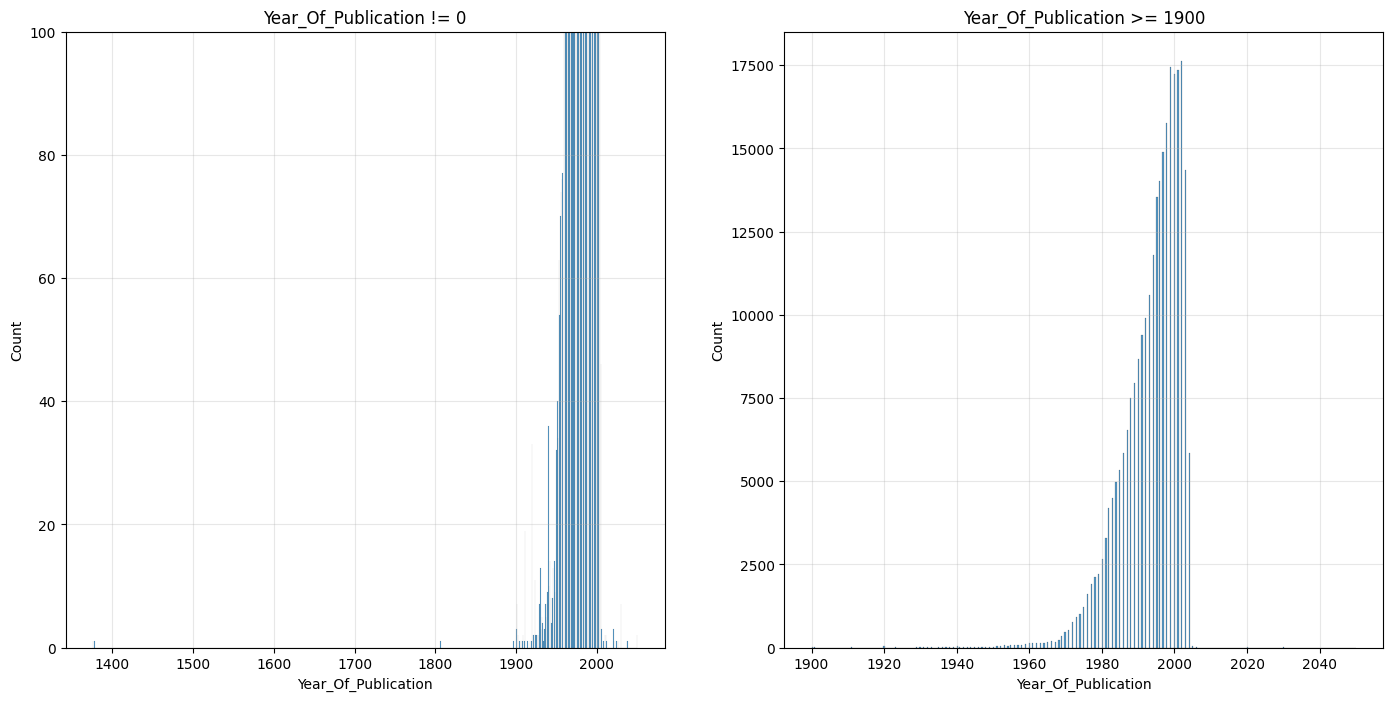

In [15]:
fig, ax = plt.subplots(ncols=2, nrows=1, figsize=(17, 8))

sns.histplot(data=df_books[df_books['Year_Of_Publication'] != 0], x='Year_Of_Publication', ax=ax[0])
ax[0].grid(True, alpha=0.3)
ax[0].set_title('Year_Of_Publication != 0')
ax[0].set_ylim(0, 100)

sns.histplot(data=df_books[df_books['Year_Of_Publication'] >= 1900], x='Year_Of_Publication', ax=ax[1])
ax[1].grid(True, alpha=0.3)
ax[1].set_title('Year_Of_Publication >= 1900')

### Ratings

In [16]:
df_ratings.head()

,User_ID,ISBN,Book_Rating
0,276725,034545104X,0
1,276726,0155061224,5
2,276727,0446520802,0
3,276729,052165615X,3
4,276729,0521795028,6


Text(0.5, 1.0, 'Without 0')

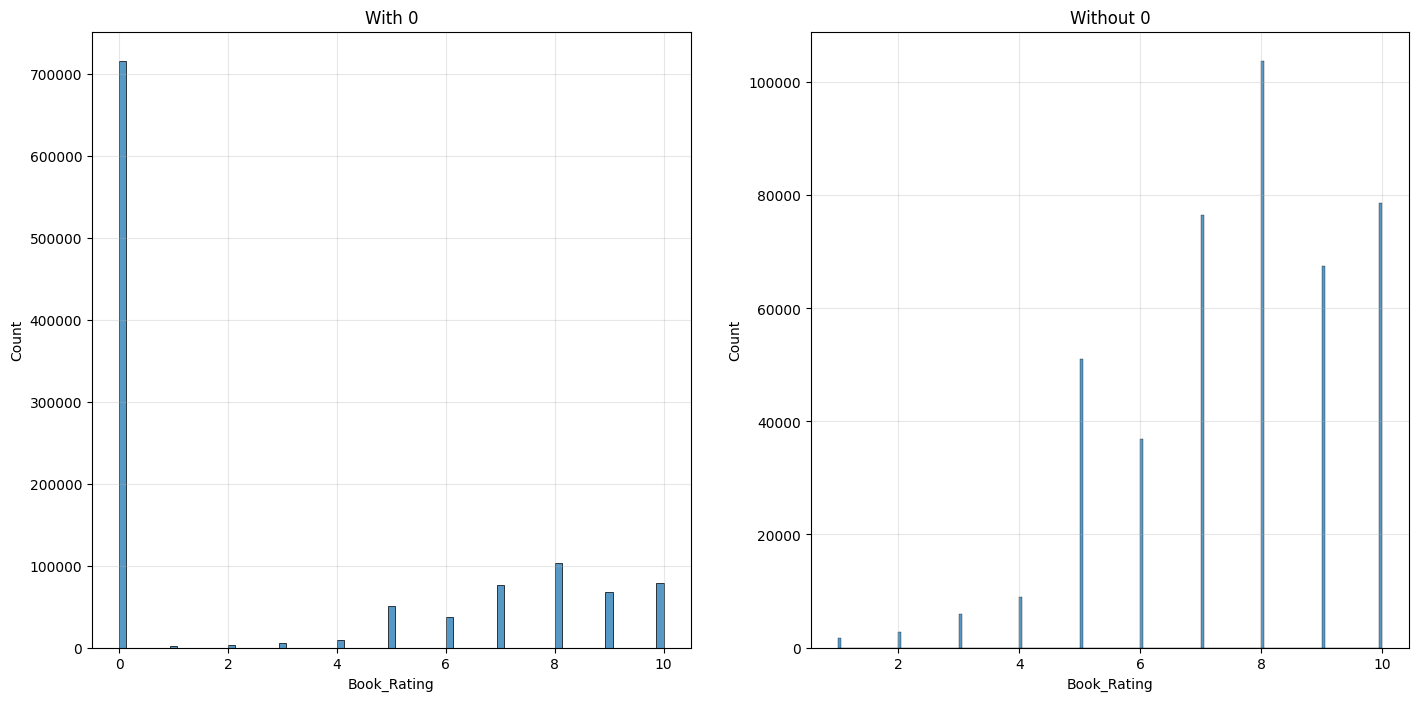

In [17]:
fig, ax = plt.subplots(ncols=2, nrows=1, figsize=(17, 8))

sns.histplot(data=df_ratings, x='Book_Rating', ax=ax[0])
ax[0].grid(True, alpha=0.3)
ax[0].set_title('With 0')

sns.histplot(data=df_ratings[df_ratings['Book_Rating'] != 0], x='Book_Rating', ax=ax[1])
ax[1].grid(True, alpha=0.3)
ax[1].set_title('Without 0')

In [18]:
# Will consider `0` value in `Book_Rating` column as rating absence so won't use it in future work
df_ratings = df_ratings[df_ratings['Book_Rating'] != 0].reset_index(drop=True)

### Users

In [19]:
df_users.head()

,User_ID,Location,Age
0,1,"nyc, new york, usa",NaN
1,2,"stockton, california, usa",18.0
2,3,"moscow, yukon territory, russia",NaN
3,4,"porto, v.n.gaia, portugal",17.0
4,5,"farnborough, hants, united kingdom",NaN


In [20]:
df_users.isna().sum()

User_ID          0
Location         0
Age         110762
dtype: int64

In [21]:
# Drop NaNs in age because age is the main goal in research
df_users = df_users.dropna(axis=0).reset_index(drop=True)

In [22]:
# Some `Age` values seem to be impossible. Change them
display(df_users.describe())

df_users.loc[df_users['Age'] > 100, 'Age'] = 100

,User_ID,Age
count,168096.000000,168096.000000
mean,139394.611865,34.751434
std,80561.659564,14.428097
min,2.000000,0.000000
25%,69914.750000,24.000000
50%,139363.500000,32.000000
75%,209162.500000,44.000000
max,278855.000000,244.000000


In [23]:
# Transform `Location` values into lower case to prevent errors because of letters' size
df_users['Location'] = df_users['Location'].apply(lambda x: x.lower())

In [24]:
# Create `Country` column from `Location`
def country_highlighter(location):
    try:
        return location.split(',')[2]
    except:
        return 'NaN'
    
df_users['Country'] = df_users['Location'].apply(lambda x: country_highlighter(x))

In [25]:
display(df_users.head())
display(df_users[df_users['Country'] == 'NaN'].head())

,User_ID,Location,Age,Country
0,2,"stockton, california, usa",18.0,usa
1,4,"porto, v.n.gaia, portugal",17.0,portugal
2,6,"santa monica, california, usa",61.0,usa
3,10,"albacete, wisconsin, spain",26.0,spain
4,11,"melbourne, victoria, australia",14.0,australia


,User_ID,Location,Age,Country
17875,29420,"st. louis, missouri",68.0,NaN
80947,134377,lawrenceville,30.0,NaN


## Merging

In [26]:
df_books.head()

,ISBN,Book_Title,Book_Author,Year_Of_Publication,Publisher
0,0195153448,classical mythology,mark p. o. morford,2002,oxford university press
1,0002005018,clara callan,richard bruce wright,2001,harperflamingo canada
2,0060973129,decision in normandy,carlo d'este,1991,harperperennial
3,0374157065,flu: the story of the great influenza pandemic of 1918 and the search for the virus that caused it,gina bari kolata,1999,farrar straus giroux
4,0393045218,the mummies of urumchi,e. j. w. barber,1999,w. w. norton &amp; company


In [27]:
df_users.head()

,User_ID,Location,Age,Country
0,2,"stockton, california, usa",18.0,usa
1,4,"porto, v.n.gaia, portugal",17.0,portugal
2,6,"santa monica, california, usa",61.0,usa
3,10,"albacete, wisconsin, spain",26.0,spain
4,11,"melbourne, victoria, australia",14.0,australia


In [28]:
df_ratings.head()

,User_ID,ISBN,Book_Rating
0,276726,0155061224,5
1,276729,052165615X,3
2,276729,0521795028,6
3,276736,3257224281,8
4,276737,0600570967,6


In [29]:
df_users_ratings = df_users.merge(right=df_ratings, how='inner', on='User_ID')
df_users_ratings

,User_ID,Location,Age,Country,ISBN,Book_Rating
0,10,"albacete, wisconsin, spain",26.0,spain,8477024456,6
1,19,"weston, ,",14.0,,0375759778,7
2,42,"appleton, wisconsin, usa",17.0,usa,0553582747,7
3,44,"black mountain, north carolina, usa",51.0,usa,0440223571,8
4,51,"renton, washington, usa",34.0,usa,0440225701,9
...,...,...,...,...,...,...
305272,278851,"dallas, texas, usa",33.0,usa,0914511211,8
305273,278851,"dallas, texas, usa",33.0,usa,1558531025,8
305274,278851,"dallas, texas, usa",33.0,usa,1569661057,10
305275,278851,"dallas, texas, usa",33.0,usa,1885071213,7


In [30]:
df_merged = df_users_ratings.merge(df_books, how='inner', on='ISBN')
df_merged

,User_ID,Location,Age,Country,ISBN,Book_Rating,Book_Title,Book_Author,Year_Of_Publication,Publisher
0,19,"weston, ,",14.0,,0375759778,7,prague : a novel,arthur phillips,2003,random house trade paperbacks
1,42,"appleton, wisconsin, usa",17.0,usa,0553582747,7,from the corner of his eye,dean koontz,2001,bantam books
2,44,"black mountain, north carolina, usa",51.0,usa,0440223571,8,this year it will be different: and other stories,maeve binchy,1997,dell
3,51,"renton, washington, usa",34.0,usa,0440225701,9,the street lawyer,john grisham,1999,dell
4,56,"cheyenne, wyoming, usa",24.0,usa,0671623249,7,lonesome dove,larry mcmurtry,1986,pocket
...,...,...,...,...,...,...,...,...,...,...
269616,278851,"dallas, texas, usa",33.0,usa,0914511211,8,1996-97 texas almanac and state industrial guide (paper),dallas morning news,1995,andrews mcmeel pub
269617,278851,"dallas, texas, usa",33.0,usa,1558531025,8,life's little instruction book (life's little instruction books (paperback)),h. jackson brown,1991,thomas nelson
269618,278851,"dallas, texas, usa",33.0,usa,1569661057,10,"dallas street map guide and directory, 2000 edition",mapsco,1999,american map corporation
269619,278851,"dallas, texas, usa",33.0,usa,1885071213,7,"highpoint adventures, a pocket guide to the 50 state highpoints",charlie winger,1999,sequoia publishing


In [31]:
from scipy.sparse import csr_matrix

# One rate for pair (user, book). If there is duplicated rates - take mean
interactions = df_merged.groupby(['User_ID', 'ISBN'], as_index=False)['Book_Rating'].mean()

# Change users' and books' ids sequential numbers of rows and columns
user_rows, user_ids = pd.factorize(interactions['User_ID'])
book_cols, book_ids = pd.factorize(interactions['ISBN'])

ratings = interactions['Book_Rating'].to_numpy(dtype=np.float32)

# Create sparse matrix:
# csr_matrix((values, (row_nums, col_nums)),
#            shape=(rows_len, cols_len)
#            )
X = csr_matrix(
    (ratings, (user_rows, book_cols)),
    shape=(len(user_ids), len(book_ids)),
)

# Set age in the same order as users in X
y = df_users.set_index('User_ID').loc[user_ids, 'Age'].to_numpy()

sp_m_shape = X.shape
sp_m_cells_count = sp_m_shape[0] * sp_m_shape[1]
print(f'Matrix size: {sp_m_shape} | Total cells count: {sp_m_cells_count}')
print('Saved rates number:', X.nnz)
print(f'Fraction of non-zero elements: {(X.nnz / sp_m_cells_count):.4%}')

Matrix size: (40543, 119948) | Total cells count: 4863051764
Saved rates number: 269621
Fraction of non-zero elements: 0.0055%


## Splitting

In [32]:
from sklearn.model_selection import train_test_split

X_train, X_val_test, y_train, y_val_test = train_test_split(X, y, test_size=0.4, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_val_test, y_val_test, test_size=0.5, random_state=42)

## Modelling

In [33]:
import time

from sklearn.metrics import root_mean_squared_error, mean_absolute_error
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV

results_df = pd.DataFrame(columns=['model', 'RMSE', 'MAE'])

def add_results(true, preds, name):
    rmse = root_mean_squared_error(true, preds)
    mae = mean_absolute_error(true, preds)
    results_df.loc[len(results_df)] = [name, rmse, mae]


def train_and_evaluate(X_tr, X_v, y_tr, y_v, name, lasso_combs_num=5, forest_combs_num=4):
    """Train Linear Regression, Lasso and Random Forest on the given data and log metrics."""
    np.random.seed(42)
    scoring = {'r2': 'r2', 'RMSE': 'neg_root_mean_squared_error',
               'MAE': 'neg_mean_absolute_error'}

    # Lasso grid search
    model_lasso_gridsearch = RandomizedSearchCV(estimator=Lasso(random_state=42),
                                                param_distributions={'alpha': np.random.uniform(0.05, 1, lasso_combs_num),
                                                                     'max_iter': np.random.randint(100, 1000, lasso_combs_num)},
                                                n_iter=lasso_combs_num,
                                                cv=2, return_train_score=True, scoring=scoring, refit='r2',
                                                random_state=42)
    model_lasso_gridsearch.fit(X_tr, y_tr)

    # Random Forest grid search
    model_forest_gridsearch = RandomizedSearchCV(estimator=RandomForestRegressor(random_state=42, n_jobs=-1),
                                                 param_distributions={'n_estimators': np.random.randint(25, 50, forest_combs_num),
                                                                      'min_samples_split': np.random.randint(2, 10, forest_combs_num),
                                                                      'max_depth': np.random.randint(2, 12, forest_combs_num)},
                                                 n_iter=forest_combs_num,
                                                 cv=2, return_train_score=True, scoring=scoring, refit='r2',
                                                 random_state=42)
    model_forest_gridsearch.fit(X_tr, y_tr)
    
    gs_disp_feats = ['rank_test_r2',
                     'mean_train_r2', 'std_train_r2', 'mean_test_r2', 'std_test_r2',
                     'mean_train_RMSE', 'std_train_RMSE', 'mean_test_RMSE', 'std_test_RMSE',
                     'mean_train_MAE', 'std_train_MAE', 'mean_test_MAE', 'std_test_MAE',
                     'mean_fit_time', 'std_fit_time', 'params']
    for model_name, search in [('Lasso', model_lasso_gridsearch),
                               ('Forest', model_forest_gridsearch)]:
        stats_df = pd.DataFrame(search.cv_results_)
        # sklearn maximizes negative error scores; show positive errors in the table
        for metric in ['RMSE', 'MAE']:
            for split in ['train', 'test']:
                stats_df[f'mean_{split}_{metric}'] *= -1
        print(f'{model_name} stats:')
        display(stats_df[gs_disp_feats].sort_values('rank_test_r2'))

    # Build final models with the best params
    models = {'Linear Regression': LinearRegression(),
              'Lasso': Lasso(**model_lasso_gridsearch.best_params_),
              'Random Forest': RandomForestRegressor(**model_forest_gridsearch.best_params_, random_state=42, n_jobs=-1)}

    for model_name, model in models.items():
        model.fit(X_tr, y_tr)
        add_results(y_v, model.predict(X_v), f'{model_name} ({name})')

    return models


### Modelling without dimension reducing

In [34]:
# Models on the initial sparse features
t0 = time.time()
models_original = train_and_evaluate(X_train, X_val, y_train, y_val, 'without dim. red.')
original_time = time.time() - t0
print(f'Training time (without dim. red.): {original_time:.2f}s')

Lasso stats:


,rank_test_r2,mean_train_r2,std_train_r2,mean_test_r2,std_test_r2,mean_train_RMSE,std_train_RMSE,mean_test_RMSE,std_test_RMSE,mean_train_MAE,std_train_MAE,mean_test_MAE,std_test_MAE,mean_fit_time,std_fit_time,params
3,1,1.585547e-03,1.008076e-03,0.000471,8.393643e-05,14.282229,0.021036,14.290189,0.013234,11.504849,0.008600,11.510567,0.005535,2.748160,0.031090,"{'max_iter': 558, 'alpha': 0.19821770842031466}"
0,2,-2.442491e-15,1.776357e-15,-0.000079,1.537096e-07,14.293559,0.013837,14.294124,0.013836,11.515583,0.016931,11.515380,0.003650,2.766850,0.016830,"{'max_iter': 558, 'alpha': 0.9531785910894204}"
1,2,-2.442491e-15,1.776357e-15,-0.000079,1.537096e-07,14.293559,0.013837,14.294124,0.013836,11.515583,0.016931,11.515380,0.003650,2.742423,0.019224,"{'max_iter': 314, 'alpha': 0.6187255599871848}"
2,2,-2.442491e-15,1.776357e-15,-0.000079,1.537096e-07,14.293559,0.013837,14.294124,0.013836,11.515583,0.016931,11.515380,0.003650,2.753562,0.003746,"{'max_iter': 566, 'alpha': 0.40581311290499433}"
4,2,-2.442491e-15,1.776357e-15,-0.000079,1.537096e-07,14.293559,0.013837,14.294124,0.013836,11.515583,0.016931,11.515380,0.003650,2.788589,0.000264,"{'max_iter': 314, 'alpha': 0.7453942447208348}"


Forest stats:


,rank_test_r2,mean_train_r2,std_train_r2,mean_test_r2,std_test_r2,mean_train_RMSE,std_train_RMSE,mean_test_RMSE,std_test_RMSE,mean_train_MAE,std_train_MAE,mean_test_MAE,std_test_MAE,mean_fit_time,std_fit_time,params
3,1,0.009917,0.000019,-0.000081,0.000191,14.222509,0.013634,14.294136,0.012473,11.490750,0.018477,11.510805,0.003454,8.588544,0.166862,"{'n_estimators': 45, 'min_samples_split': 3, 'max_depth': 3}"
0,2,0.018288,0.000155,-0.000283,0.000327,14.162255,0.014826,14.295576,0.011505,11.465361,0.016000,11.506333,0.006356,8.847091,0.047161,"{'n_estimators': 45, 'min_samples_split': 7, 'max_depth': 6}"
1,3,0.018334,0.000162,-0.000368,0.000303,14.161928,0.014879,14.296188,0.011676,11.465373,0.015387,11.507073,0.006824,6.537830,0.027546,"{'n_estimators': 32, 'min_samples_split': 6, 'max_depth': 6}"
2,4,0.025766,0.000062,-0.000446,0.000248,14.108218,0.014103,14.296745,0.012069,11.437358,0.012149,11.502787,0.006349,9.386592,0.287014,"{'n_estimators': 45, 'min_samples_split': 4, 'max_depth': 9}"


Training time (without dim. red.): 166.52s


### Modelling with dimensionality reduction

In [35]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

np.random.seed(42)
n_components = 50

# PCA on the full sparse data
pca = PCA(n_components=n_components, random_state=42)
t0 = time.time()
X_train_pca = pca.fit_transform(X_train)
X_val_pca = pca.transform(X_val)
pca_time = time.time() - t0
print(f'PCA fitting time: {pca_time:.2f}s | Train: {X_train_pca.shape}, Val: {X_val_pca.shape}')

# Subsample for UMAP and TSNE (dense conversion and algorithms' speed)
subsample_size = 1000
subsample_idx = np.random.choice(X_train.shape[0], size=subsample_size, replace=False)
X_train_sub = X_train[subsample_idx].toarray().astype(np.float32)
y_train_sub = y_train[subsample_idx]

val_subsample_size = 500
val_subsample_idx = np.random.choice(X_val.shape[0], size=val_subsample_size, replace=False)
X_val_sub = X_val[val_subsample_idx].toarray().astype(np.float32)
y_val_sub = y_val[val_subsample_idx]

# UMAP on the subsampled data
umap_reducer = umap.UMAP(n_components=n_components, random_state=42, n_neighbors=15, min_dist=0.1)
t0 = time.time()
X_train_umap = umap_reducer.fit_transform(X_train_sub)
X_val_umap = umap_reducer.transform(X_val_sub)
umap_time = time.time() - t0
print(f'UMAP fitting time: {umap_time:.2f}s | Train: {X_train_umap.shape}, Val: {X_val_umap.shape}')

# TSNE on the subsampled data
# TSNE has no transform method, so train and val are embedded together and then split
# barnes_hut supports n_components < 4, that is why the number of components is limited
tsne_n_components = 3
tsne = TSNE(n_components=tsne_n_components, random_state=42, perplexity=30,
            learning_rate='auto', init='random')
t0 = time.time()
X_all_tsne = tsne.fit_transform(np.vstack([X_train_sub, X_val_sub]))
tsne_time = time.time() - t0
X_train_tsne = X_all_tsne[:subsample_size]
X_val_tsne = X_all_tsne[subsample_size:]
print(f'TSNE fitting time: {tsne_time:.2f}s | Train: {X_train_tsne.shape}, Val: {X_val_tsne.shape}')

PCA fitting time: 1.83s | Train: (24325, 50), Val: (8109, 50)


d:\Download\distrib\Python\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP fitting time: 166.07s | Train: (1000, 50), Val: (500, 50)
TSNE fitting time: 73.54s | Train: (1000, 3), Val: (500, 3)


In [36]:
# Models on the reduced features
t0 = time.time()
models_pca = train_and_evaluate(X_train_pca, X_val_pca, y_train, y_val, 'PCA')
pca_train_time = time.time() - t0

t0 = time.time()
models_umap = train_and_evaluate(X_train_umap, X_val_umap, y_train_sub, y_val_sub, 'UMAP')
umap_train_time = time.time() - t0

t0 = time.time()
models_tsne = train_and_evaluate(X_train_tsne, X_val_tsne, y_train_sub, y_val_sub, 'TSNE')
tsne_train_time = time.time() - t0


Lasso stats:


,rank_test_r2,mean_train_r2,std_train_r2,mean_test_r2,std_test_r2,mean_train_RMSE,std_train_RMSE,mean_test_RMSE,std_test_RMSE,mean_train_MAE,std_train_MAE,mean_test_MAE,std_test_MAE,mean_fit_time,std_fit_time,params
3,1,3.369159e-03,5.070906e-04,0.001686,8.358059e-05,14.269464,0.017444,14.281504,0.014423,11.491789,0.012023,11.503231,0.000872,0.058397,0.008456,"{'max_iter': 558, 'alpha': 0.19821770842031466}"
2,2,1.237276e-04,1.237276e-04,-0.000070,9.422394e-06,14.292676,0.014720,14.294058,0.013770,11.514733,0.016080,11.515278,0.003752,0.020620,0.003078,"{'max_iter': 566, 'alpha': 0.40581311290499433}"
1,3,3.611385e-05,3.611385e-05,-0.000074,4.718487e-06,14.293302,0.014095,14.294091,0.013804,11.515272,0.016620,11.515328,0.003702,0.017461,0.001424,"{'max_iter': 314, 'alpha': 0.6187255599871848}"
4,4,2.473546e-05,2.473546e-05,-0.000076,3.056490e-06,14.293383,0.014013,14.294103,0.013816,11.515386,0.016733,11.515347,0.003683,0.015391,0.000718,"{'max_iter': 314, 'alpha': 0.7453942447208348}"
0,5,-2.442491e-15,1.776357e-15,-0.000079,1.537096e-07,14.293559,0.013837,14.294124,0.013836,11.515583,0.016931,11.515380,0.003650,0.045496,0.025829,"{'max_iter': 558, 'alpha': 0.9531785910894204}"


Forest stats:


,rank_test_r2,mean_train_r2,std_train_r2,mean_test_r2,std_test_r2,mean_train_RMSE,std_train_RMSE,mean_test_RMSE,std_test_RMSE,mean_train_MAE,std_train_MAE,mean_test_MAE,std_test_MAE,mean_fit_time,std_fit_time,params
2,1,0.277679,0.001238,0.055918,0.001807,12.148002,0.001349,13.888186,0.026739,9.657211,0.024611,11.088822,0.028043,3.255740,0.013459,"{'n_estimators': 45, 'min_samples_split': 4, 'max_depth': 9}"
0,2,0.124221,0.001544,0.052566,0.001453,13.376361,0.024744,13.912817,0.024139,10.707518,0.025101,11.130731,0.022241,2.587815,0.000522,"{'n_estimators': 45, 'min_samples_split': 7, 'max_depth': 6}"
1,3,0.124181,0.001979,0.052162,0.000833,13.376663,0.028066,13.915784,0.019583,10.706909,0.025999,11.135807,0.019576,1.912855,0.069091,"{'n_estimators': 32, 'min_samples_split': 6, 'max_depth': 6}"
3,4,0.045806,0.001530,0.032995,0.000162,13.962363,0.024712,14.055774,0.012429,11.207528,0.005746,11.276643,0.009614,1.251535,0.030089,"{'n_estimators': 45, 'min_samples_split': 3, 'max_depth': 3}"


Lasso stats:


,rank_test_r2,mean_train_r2,std_train_r2,mean_test_r2,std_test_r2,mean_train_RMSE,std_train_RMSE,mean_test_RMSE,std_test_RMSE,mean_train_MAE,std_train_MAE,mean_test_MAE,std_test_MAE,mean_fit_time,std_fit_time,params
0,1,-1.232348e-14,2.775558e-15,-0.002284,0.000178,14.00982,0.547665,14.025761,0.547043,11.396936,0.638808,11.423504,0.726896,0.002725,0.000707,"{'max_iter': 558, 'alpha': 0.9531785910894204}"
1,1,-1.232348e-14,2.775558e-15,-0.002284,0.000178,14.00982,0.547665,14.025761,0.547043,11.396936,0.638808,11.423504,0.726896,0.002107,0.000049,"{'max_iter': 314, 'alpha': 0.6187255599871848}"
2,1,-1.232348e-14,2.775558e-15,-0.002284,0.000178,14.00982,0.547665,14.025761,0.547043,11.396936,0.638808,11.423504,0.726896,0.003139,0.000904,"{'max_iter': 566, 'alpha': 0.40581311290499433}"
3,1,-1.232348e-14,2.775558e-15,-0.002284,0.000178,14.00982,0.547665,14.025761,0.547043,11.396936,0.638808,11.423504,0.726896,0.002511,0.000494,"{'max_iter': 558, 'alpha': 0.19821770842031466}"
4,1,-1.232348e-14,2.775558e-15,-0.002284,0.000178,14.00982,0.547665,14.025761,0.547043,11.396936,0.638808,11.423504,0.726896,0.001805,0.000211,"{'max_iter': 314, 'alpha': 0.7453942447208348}"


... (2 outputs left out)

Lasso stats:


,rank_test_r2,mean_train_r2,std_train_r2,mean_test_r2,std_test_r2,mean_train_RMSE,std_train_RMSE,mean_test_RMSE,std_test_RMSE,mean_train_MAE,std_train_MAE,mean_test_MAE,std_test_MAE,mean_fit_time,std_fit_time,params
0,1,0.002600,0.000548,-0.009328,0.000192,13.991743,0.550793,14.074960,0.548874,11.378513,0.641109,11.452455,0.747821,0.003640,0.000522,"{'max_iter': 558, 'alpha': 0.9531785910894204}"
4,2,0.002604,0.000548,-0.009455,0.000201,13.991717,0.550795,14.075840,0.548850,11.378451,0.641052,11.453037,0.748040,0.003008,0.000011,"{'max_iter': 314, 'alpha': 0.7453942447208348}"
1,3,0.002606,0.000548,-0.009532,0.000206,13.991705,0.550795,14.076379,0.548835,11.378413,0.641018,11.453391,0.748174,0.003780,0.000757,"{'max_iter': 314, 'alpha': 0.6187255599871848}"
2,4,0.002608,0.000548,-0.009663,0.000214,13.991689,0.550796,14.077291,0.548810,11.378350,0.640960,11.453987,0.748398,0.001996,0.000004,"{'max_iter': 566, 'alpha': 0.40581311290499433}"
3,5,0.002609,0.000548,-0.009792,0.000223,13.991680,0.550797,14.078186,0.548786,11.378288,0.640904,11.454568,0.748617,0.002506,0.000505,"{'max_iter': 558, 'alpha': 0.19821770842031466}"


Forest stats:


,rank_test_r2,mean_train_r2,std_train_r2,mean_test_r2,std_test_r2,mean_train_RMSE,std_train_RMSE,mean_test_RMSE,std_test_RMSE,mean_train_MAE,std_train_MAE,mean_test_MAE,std_test_MAE,mean_fit_time,std_fit_time,params
3,1,0.101213,0.004815,-0.014841,0.007518,13.283268,0.554786,14.111259,0.499432,10.813109,0.659517,11.494857,0.678586,0.156092,0.002156,"{'n_estimators': 45, 'min_samples_split': 3, 'max_depth': 3}"
0,2,0.286684,0.032137,-0.034979,0.001342,11.839838,0.729040,14.252375,0.547922,9.659252,0.713720,11.578363,0.704214,0.188594,0.022953,"{'n_estimators': 45, 'min_samples_split': 7, 'max_depth': 6}"
1,3,0.285145,0.036743,-0.040455,0.002345,11.853162,0.767407,14.291012,0.574739,9.654006,0.746308,11.597611,0.724086,0.130651,0.005323,"{'n_estimators': 32, 'min_samples_split': 6, 'max_depth': 6}"
2,4,0.508289,0.054176,-0.068260,0.000093,9.830204,0.925467,14.480109,0.566678,7.989596,0.769116,11.710520,0.679343,0.143744,0.004589,"{'n_estimators': 45, 'min_samples_split': 4, 'max_depth': 9}"


In [37]:
# Compare Lasso coefficients before and after dimensionality reduction
# Reduced features refer to components, not individual books
top_n = 5

def get_lasso_coefs(model, features, name):
    coefs = np.asarray(model.coef_).ravel()
    zeroed = np.flatnonzero(coefs == 0)
    nonzero = np.flatnonzero(coefs != 0)
    # Sort by signed coefficient value, descending
    strongest = nonzero[np.argsort(-coefs[nonzero], kind='stable')][:top_n]
    zeroed = sorted(zeroed, key=lambda i: features[i])

    return {
        'Method': name,
        'Top-5 coefs': [(features[i], float(coefs[i])) for i in strongest],
        'Num of zeroed coefs': len(zeroed),
        'Total components num': len(coefs),
        'Zeroed components fraction': len(zeroed) / len(coefs),
        'Zeroed coefs': [(features[i], 0.0) for i in zeroed],
    }

lasso_features_df = pd.DataFrame([
    get_lasso_coefs(models_original['Lasso'], list(map(str, book_ids)), 'Without method'),
    get_lasso_coefs(models_pca['Lasso'],
                    [f'PC_{i}' for i in range(len(models_pca['Lasso'].coef_))], 'PCA'),
    get_lasso_coefs(models_umap['Lasso'],
                    [f'UMAP_{i}' for i in range(len(models_umap['Lasso'].coef_))], 'UMAP'),
    get_lasso_coefs(models_tsne['Lasso'],
                    [f'TSNE_{i}' for i in range(len(models_tsne['Lasso'].coef_))], 'TSNE'),
])

display(lasso_features_df)

,Method,Top-5 coefs,Num of zeroed coefs,Total components num,Zeroed components fraction,Zeroed coefs
0,Without method,"[(0385504209, 0.167086660861969), (0142001740, 0.008970944210886955), (059035342X, -0.03861483931541443), (0316769487, -0.1269741654396057)]",119944,119948,0.999967,"[(0000913154, 0.0), (0001047973, 0.0), (000104799X, 0.0), (0001048082, 0.0), (0001055607, 0.0), (0001056107, 0.0), (0001360469, 0.0), (0001374362, 0.0), (0001374869, 0.0), (000160418X, 0.0), (0001714600, 0.0), (0001811819, 0.0), (0001821326, 0.0), (0001837397, 0.0), (0001841572, 0.0), (0001845039, 0.0), (0001900277, 0.0), (0001935968, 0.0), (0001939203, 0.0), (0001941941, 0.0), (0001941968, 0.0), (0001945203, 0.0), (0001952803, 0.0), (0001953877, 0.0), (0001981307, 0.0), (0001981625, 0.0), (0002000369, 0.0), (0002000547, 0.0), (0002005018, 0.0), (0002005050, 0.0), (0002005395, 0.0), (0002005557, 0.0), (0002111314, 0.0), (0002115328, 0.0), (0002116286, 0.0), (0002118580, 0.0), (0002154900, 0.0), (0002154978, 0.0), (0002157446, 0.0), (000215871X, 0.0), (0002160099, 0.0), (0002163578, 0.0), (0002165368, 0.0), (0002176181, 0.0), (0002176432, 0.0), (0002179695, 0.0), (0002184974, 0.0), (0002190915, 0.0), (0002191792, 0.0), (0002192152, 0.0), (0002197154, 0.0), (0002197286, 0.0), (0002199009, 0.0), (0002210436, 0.0), (0002210479, 0.0), (0002210967, 0.0), (0002211890, 0.0), (0002214067, 0.0), (0002216140, 0.0), (000221766X, 0.0), (0002219980, 0.0), (0002222469, 0.0), (0002223929, 0.0), (0002224216, 0.0), (0002226162, 0.0), (000222674X, 0.0), (0002227150, 0.0), (0002228394, 0.0), (0002231352, 0.0), (0002233509, 0.0), (0002235390, 0.0), (0002237458, 0.0), (0002237857, 0.0), (0002239183, 0.0), (0002240114, 0.0), (0002242591, 0.0), (0002243792, 0.0), (0002243806, 0.0), (0002243962, 0.0), (0002244098, 0.0), (0002245728, 0.0), (000225056X, 0.0), (0002250985, 0.0), (0002251760, 0.0), (0002251892, 0.0), (0002252031, 0.0), (0002252066, 0.0), (0002252341, 0.0), (0002253178, 0.0), (0002253305, 0.0), (0002253402, 0.0), (0002254123, 0.0), (0002254131, 0.0), (000225414X, 0.0), (0002255006, 0.0), (0002255014, 0.0), (0002255081, 0.0), (0002255103, 0.0), (0002255146, 0.0), (0002255464, 0.0), ...]"
1,PCA,"[(PC_34, 0.14467862248420715), (PC_29, 0.11792555451393127), (PC_22, 0.11324580758810043), (PC_24, 0.08083885163068771), (PC_18, 0.044837310910224915)]",37,50,0.740000,"[(PC_1, 0.0), (PC_10, 0.0), (PC_11, 0.0), (PC_12, 0.0), (PC_13, 0.0), (PC_14, 0.0), (PC_15, 0.0), (PC_16, 0.0), (PC_19, 0.0), (PC_20, 0.0), (PC_21, 0.0), (PC_26, 0.0), (PC_27, 0.0), (PC_28, 0.0), (PC_3, 0.0), (PC_30, 0.0), (PC_31, 0.0), (PC_32, 0.0), (PC_33, 0.0), (PC_35, 0.0), (PC_36, 0.0), (PC_37, 0.0), (PC_38, 0.0), (PC_39, 0.0), (PC_4, 0.0), (PC_40, 0.0), (PC_41, 0.0), (PC_42, 0.0), (PC_43, 0.0), (PC_44, 0.0), (PC_46, 0.0), (PC_47, 0.0), (PC_48, 0.0), (PC_6, 0.0), (PC_7, 0.0), (PC_8, 0.0), (PC_9, 0.0)]"
2,UMAP,[],50,50,1.000000,"[(UMAP_0, 0.0), (UMAP_1, 0.0), (UMAP_10, 0.0), (UMAP_11, 0.0), (UMAP_12, 0.0), (UMAP_13, 0.0), (UMAP_14, 0.0), (UMAP_15, 0.0), (UMAP_16, 0.0), (UMAP_17, 0.0), (UMAP_18, 0.0), (UMAP_19, 0.0), (UMAP_2, 0.0), (UMAP_20, 0.0), (UMAP_21, 0.0), (UMAP_22, 0.0), (UMAP_23, 0.0), (UMAP_24, 0.0), (UMAP_25, 0.0), (UMAP_26, 0.0), (UMAP_27, 0.0), (UMAP_28, 0.0), (UMAP_29, 0.0), (UMAP_3, 0.0), (UMAP_30, 0.0), (UMAP_31, 0.0), (UMAP_32, 0.0), (UMAP_33, 0.0), (UMAP_34, 0.0), (UMAP_35, 0.0), (UMAP_36, 0.0), (UMAP_37, 0.0), (UMAP_38, 0.0), (UMAP_39, 0.0), (UMAP_4, 0.0), (UMAP_40, 0.0), (UMAP_41, 0.0), (UMAP_42, 0.0), (UMAP_43, 0.0), (UMAP_44, 0.0), (UMAP_45, 0.0), (UMAP_46, 0.0), (UMAP_47, 0.0), (UMAP_48, 0.0), (UMAP_49, 0.0), (UMAP_5, 0.0), (UMAP_6, 0.0), (UMAP_7, 0.0), (UMAP_8, 0.0), (UMAP_9, 0.0)]"
3,TSNE,"[(TSNE_1, -0.0010258654365316033)]",2,3,0.666667,"[(TSNE_0, 0.0), (TSNE_2, 0.0)]"


In [38]:
# Overall results table
display(results_df)

# Fitting time comparison
time_df = pd.DataFrame({
    'method': ['without dim. red.', 'PCA', 'UMAP', 'TSNE'],
    'dim. reduction time (s)': ['-', round(pca_time, 2), round(umap_time, 2), round(tsne_time, 2)],
    'training time (s)': [round(original_time, 2), round(pca_train_time, 2),
                          round(umap_train_time, 2), round(tsne_train_time, 2)]
})
display(time_df)

,model,RMSE,MAE
0,Linear Regression (without dim. red.),28.131387,17.691060
1,Lasso (without dim. red.),14.511305,11.558320
2,Random Forest (without dim. red.),14.515702,11.562088
3,Linear Regression (PCA),14.461857,11.512213
4,Lasso (PCA),14.500298,11.547705
5,Random Forest (PCA),14.095861,11.126311
6,Linear Regression (UMAP),16.017406,11.852561
7,Lasso (UMAP),15.106697,11.507800
8,Random Forest (UMAP),15.152064,11.488633
9,Linear Regression (TSNE),15.111369,11.511323


,method,dim. reduction time (s),training time (s)
0,without dim. red.,-,166.52
1,PCA,1.83,33.73
2,UMAP,166.07,2.92
3,TSNE,73.54,2.59
